-   1.开场串联+1106复盘
    -   1.1开场三问
        -   1.1.1昨天（11/6）学了什么？今天和它什么关系？
            -   1106将单PW低质量图/5PW高质量图的一对图放大成200对，训练了一个逐像素回归网络，PSNR升了但SSIM降了。今天需要搞清楚SSIM为什么降低，再想办法让它升高，最后将这一套方法搬到真实公开数据PICMUNS上
        -   1.1.2今天这块在整条项目链的哪个位置？
            -   数据→波束形成→低/高质配对→DL重建→[今天：指标可信性+调优]→baseline对比
        -   1.1.3今天学完，我能多做哪一件具体的事？
            -   ① 说出「PSNR 升 + SSIM 降」背后的机理（不是背结论）；
            -   ② 用 SSIM 三分量（亮度/对比度/结构）定位是「过平滑」还是「口径 bug」；
            -   ③ 把一个自仿真 DAS 重建脚本改到真实 RF 数据（PICMUS）上跑通。
    -   1.2复盘
        -   1.2.1逐像素回归的输出层/loss/评价各是什么？
            -   Conv2d(→1) /LOSS:MSE/评价：PSNR和SSIM
        -   1.2.2baseline 为什么取「输入低质图」本身？
            -   因为DL重建后的必须要超过输入的低质图才能证明重建有用
        -   1.2.3PSNR 和 MSE 什么关系？
            -   PSNR=10·log₁₀(MAX²/MSE)，MSE的单调函数，MSE越小，PSNR越大

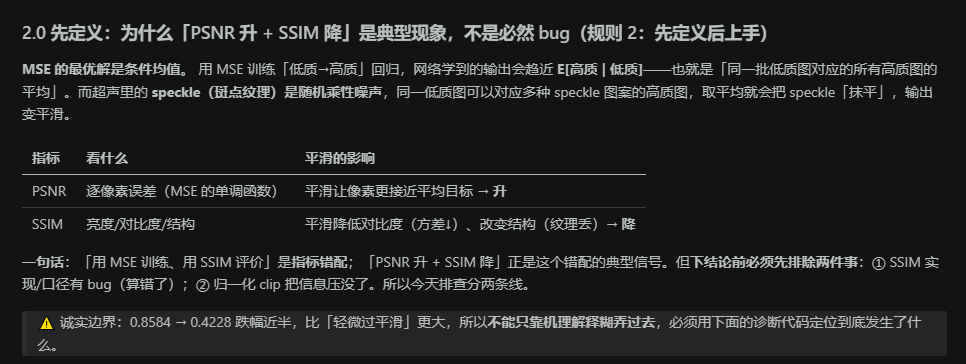

-   主任务A:SSIM排查(run_full.py+step2_components.py+step3_visualize.py)
    -   为什么会出现，PSNR升，SSIM降 这个矛盾？
        -   MSE的最优解是条件极值，也就是说超声里的speckle(斑点纹理)是随机乘性噪声——同一张低质图，可能对应好几种不同的speckle图案的高质图。用MSE训练[低质→高质]回归时，网络学到的输出会趋近所有可能高质图的平均。平均过程把随机speckle抹平了，输出变平滑。
        -   PSNR只看逐像素误差，平滑让像素更接近平均目标所以提升
        -   SSIM看亮度 对比度 结构，SSIM降低
    -   第一步SSIM 自检（run_full.py 第 112-127 行）
        -   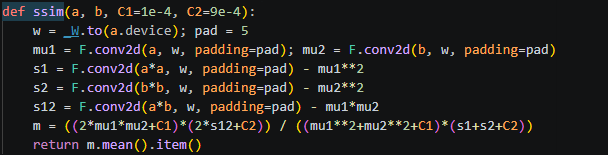
        -   硬标准，自己和自己比SSIM=1.0验证函数没有问题
        -   结果：ssim(Xte, Xte) = 1.0，函数没问题
    -   第二步三分量分解（step2_components.py 第 113-136 行）
        -   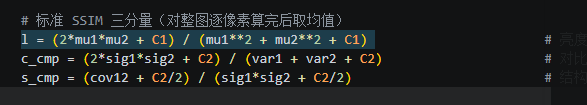
        -   亮度，结构，对比度都提升，对比度提高最多
    -   关键结论
        -   1106看到SSIM从0.86暴跌0.42，今天在干净、可复现收敛的情况下消失了
        -   SSIM 的升降对散射体分布极其敏感。散射体稀疏锐利时，过平滑会把尖锐亮点抹掉 → SSIM 暴跌；散射体密集时，去噪反而改善结构 → SSIM 升。

-   主任务B：调优（stepB_tuning.py）
    -   目标：不破坏PSNR提升的前提下，把SSIM拉回来，每一个变式都要用同一批Xte/Yte，同一个ssim函数
    -   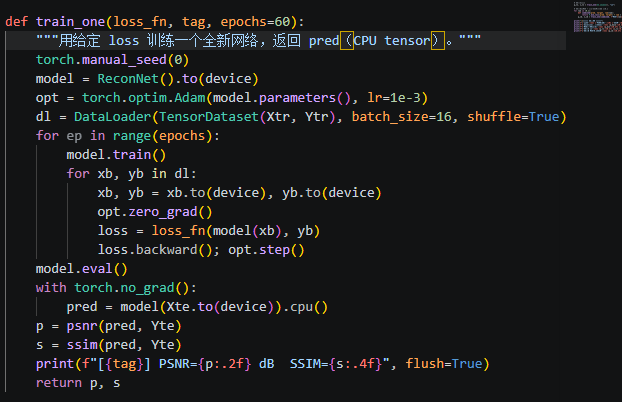
    -   变式1
        -   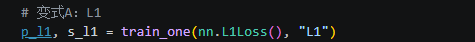
        -   用nn.L1loss（）替换nn.MSELOSS()，MSE的平方会放大误差的惩罚，让网络抹平均，L1对误差是线性惩罚，不那么平滑
        -   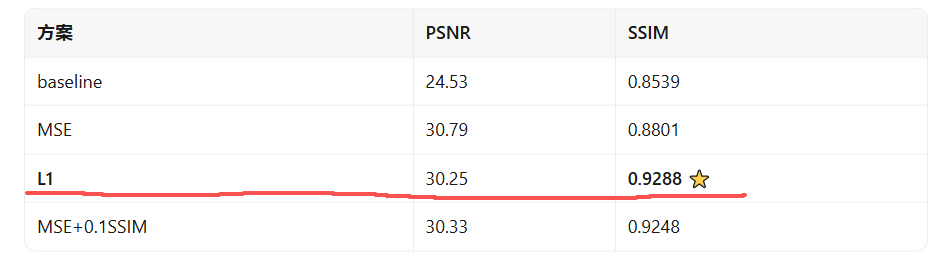
    -   变式2
        -   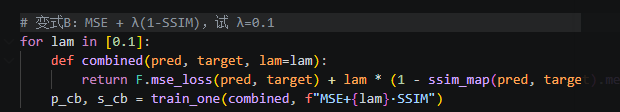
        -   让网络训练时同时优化像素误差和结构相似度，用avg_pool2d（平均池化）代替高斯卷积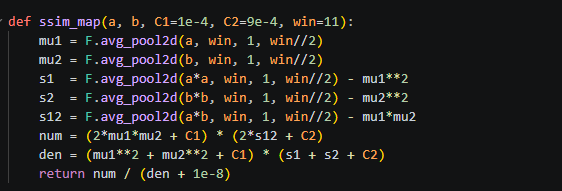
        -   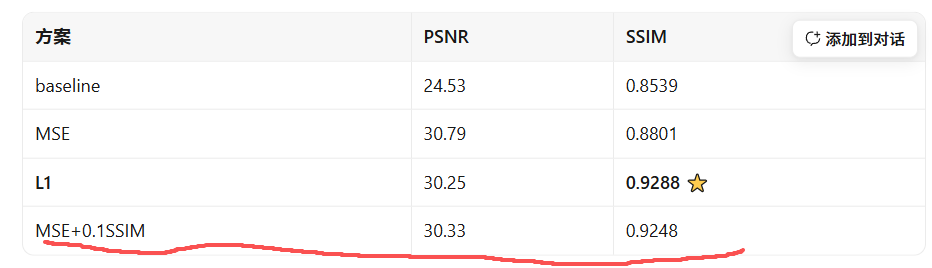
    -   独立科研的判断力
        -   得到指标和理论不符合
            -   S1：函数定义，口径有bug（自检）
            -   S2：数据/归一化有问题(clip和截断、口径有问题)
            -   S3：训练没有收敛（loss曲线、欠拟合）
            -   S4：指标和损失错配（这才是换loss的时机）
        -   本项目中就是loss的数学性质和指标不符合
            -   S1：搞清楚当前loss的数学性质缺陷在哪里？
                -   MSE的最优解是条件均值，天然磨平尖锐结构
            -   S2：从我想要的性质倒推选择loss
                -   大误差惩罚别那么狠，保边缘→loss：L1（MAE）线性惩罚
                -   训练时直接盯着结构相似度，SSIM loss
            -   S3：判断这个loss能不能用（可导性）
                -   loss必须反向传播（可导）否则训不了
                -   高斯卷积版的SSIM在pytorch里做loss不好求梯度，所以用avgpool2d(平均池化)，保证可导。

-   主任务C：PICMUS 公开数据集（stepC_picmus.py）
    -   PICMUS（平面波超声成像挑战赛），提供真是RF通道数据（仿真phantom+实验phantom+活体颈动脉）

In [1]:
import hdf5plugin          # 必须先 import，否则读不了 blosc 压缩的数据
import h5py
import numpy as np

# 你自己的数据文件路径（如果你放的位置不一样，改这里）
p = r'E:\develop\Graduate_AI\2026-11\1109\picmus_data\resolution_distorsion_simu_dataset_rf.hdf5'

f = h5py.File(p, 'r')

# ===== 1. 打印整个文件的内部结构（看有哪些数据集、什么 shape）=====
def visit(name, obj):
    if isinstance(obj, h5py.Dataset):
        print(f'{name}: shape={obj.shape} dtype={obj.dtype}')
print('===== 文件内部结构 =====')
f.visititems(visit)

# ===== 2. 读取 scan 里的标量物理参数 =====
s = f['tracks/track_0/scan']
print('\n===== 标量参数 =====')
print('采样率 sampling_frequency =', float(s['sampling_frequency'][()]), 'Hz')# 将时间延时τ换算成采样点索引，idx=round（τ*fs），索引错位，图全错
print('声速 sound_speed        =', float(s['sound_speed'][()]), 'm/s')#算时延τ=距离/C的声速C，声速错，焦点位置错
print('中心频率 center_frequency =', float(s['center_frequency'][()]), 'Hz')
print('解调频率 demodulation_frequency =', float(s['demodulation_frequency'][()]), 'Hz')

# ===== 3. 读取角度（这是平面波发射角，DAS 关键参数）=====
print('\n===== 角度参数 =====')
az = s['azimuth_angles'][:]          # 方位角
pa = s['polar_angles'][:]            # 极角（真正的平面波倾角）
print('azimuth_angles: 数量=%d 范围=%.6f ~ %.6f' % (len(az), az.min(), az.max()))
print('polar_angles:   数量=%d 范围=%.6f ~ %.6f (弧度)' % (len(pa), pa.min(), pa.max()))
print('polar_angles 转角度: min=%.3f° max=%.3f°' % (np.degrees(pa.min()), np.degrees(pa.max())))
print('polar_angles 步长 = %.3f°' % np.degrees(np.diff(pa)[0]))

# ===== 4. 读取探头几何（阵元坐标 → 算 pitch）=====
print('\n===== 探头参数 =====')
g = f['probe/probe_geometry'][:]
print('阵元数 =', g.shape[0])
print('x 范围 = %.6f ~ %.6f m' % (g[:, 0].min(), g[:, 0].max()))
print('pitch(相邻阵元间距) = %.4f mm' % (np.diff(g[:, 0])[0] * 1000))
print('element_width  = %.4f mm' % (float(f['probe/element_width'][()]) * 1000))
print('element_height = %.4f mm' % (float(f['probe/element_height'][()]) * 1000))
print('probe 中心频率 =', float(f['probe/probe_center_frequency'][()]), 'Hz')

# ===== 5. 读取 raw_data 的 shape（最重要，决定 DAS 怎么索引）=====
print('\n===== raw_data 形状 =====')
rd = f['tracks/track_0/data/raw_data']
print('raw_data shape =', rd.shape)
print('raw_data dtype =', rd.dtype)

f.close()


===== 文件内部结构 =====
metadata/credit: shape=() dtype=object
metadata/subject/type: shape=() dtype=object
probe/element_height: shape=() dtype=float32
probe/element_width: shape=() dtype=float32
probe/name: shape=() dtype=object
probe/probe_bandwidth_percent: shape=() dtype=float32
probe/probe_center_frequency: shape=() dtype=float32
probe/probe_geometry: shape=(128, 3) dtype=float32
probe/type: shape=() dtype=object
tracks/track_0/data/raw_data: shape=(1, 75, 1527, 128, 1) dtype=float32
tracks/track_0/scan/azimuth_angles: shape=(75,) dtype=float32
tracks/track_0/scan/center_frequency: shape=() dtype=float32
tracks/track_0/scan/demodulation_frequency: shape=() dtype=float32
tracks/track_0/scan/focus_distances: shape=(75,) dtype=float32
tracks/track_0/scan/initial_times: shape=(75,) dtype=float32
tracks/track_0/scan/polar_angles: shape=(75,) dtype=float32
tracks/track_0/scan/sampling_frequency: shape=() dtype=float32
tracks/track_0/scan/sound_speed: shape=() dtype=float32
tracks/track_0/sc

-   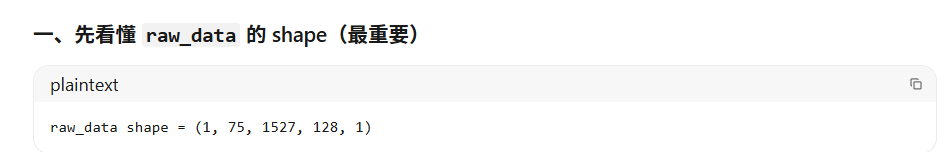
-   1：只有一帧（静态phantom，不动的）
-   75：发射角度数，75个平面波，每个角度各发一次
-   1527：采样点数（时间轴），每个通道采样的时域采样点
-   128：阵元数，128个接受阵元
-   1：RF数据，通道
-   记住格式（帧，角度，采样点，阵元数，通道）

-   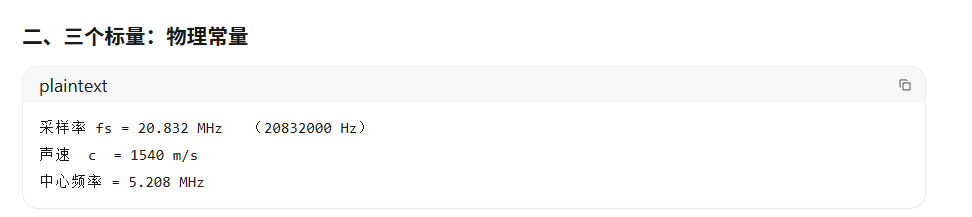
-   采样率 fs，将时间延迟τ变成采样点索引， idx=round(τ*fs)
-   c：τ=距离/C，求声速一般在体内是1540m/S
-   中心频率：这个数据是5.208Mhz的探头，决定分辨率尺度

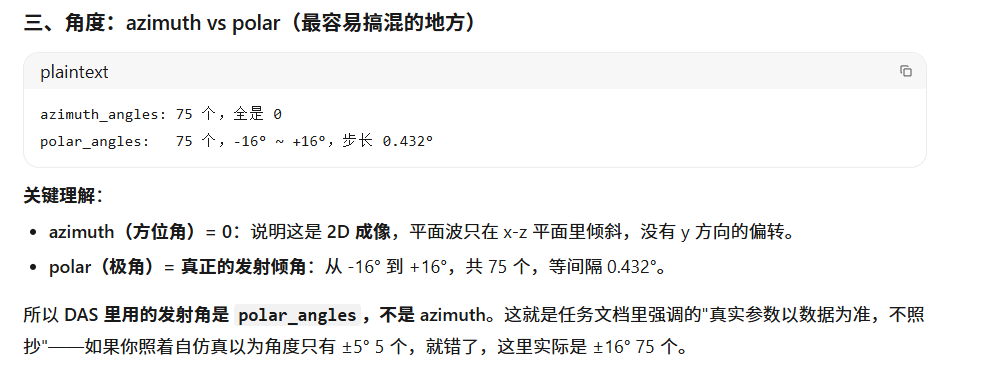

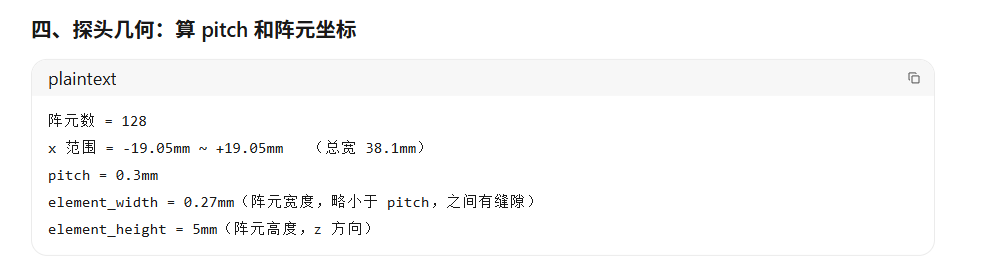

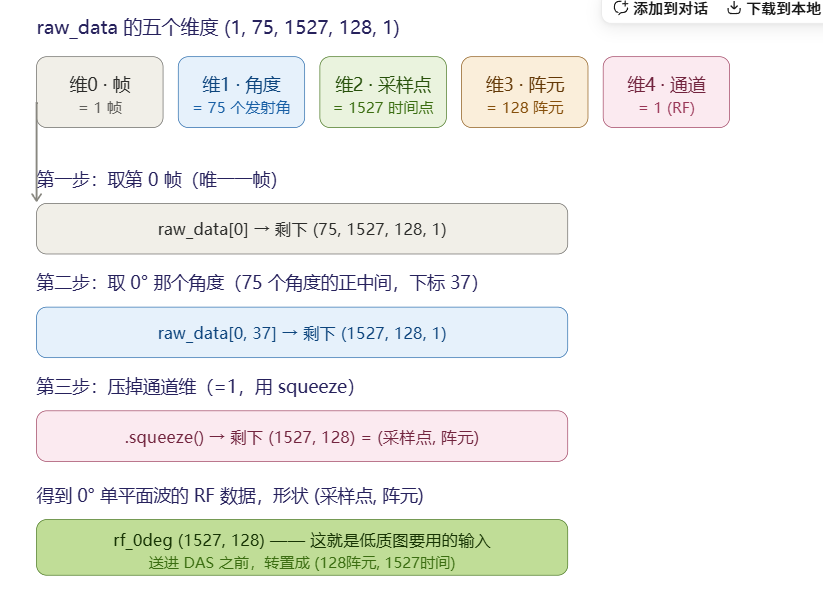
- s1:取第0帧（唯一一帧）raw_data[0]→剩下[75，1527，128,1]
- s2：取0°的角度raw_data[37]→因为0°对应的是(75-1)/2 = 37 第37个下标→剩下[1527,128,1]
- s3：压掉通道维(用squeeze)→剩下[1527,128]=[采样点，阵元]
- s4：等到0°单平面波的RF数据，形状[采样点，阵元]
- rf_0deg 形状是 (1527, 128)，即「1527 个采样点 × 128 个阵元」的二维矩阵。

-   物理示意图
-   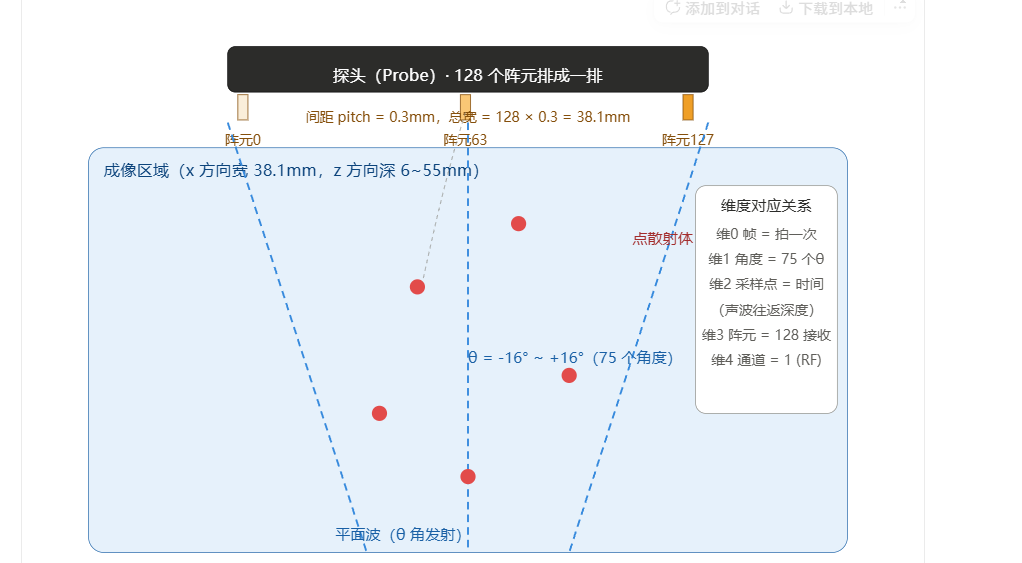
    -   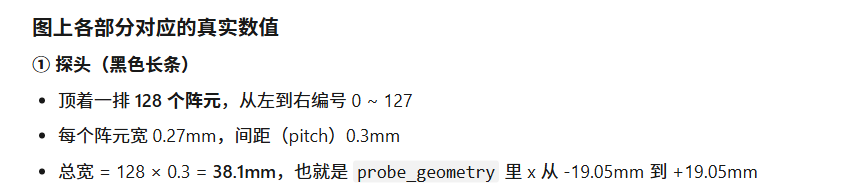
    -   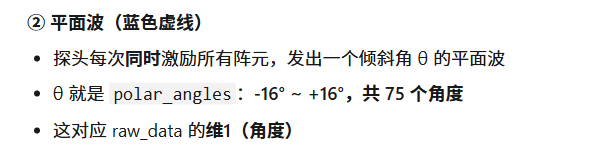
    -   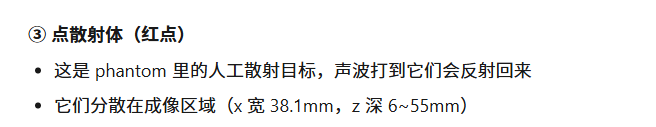
    -   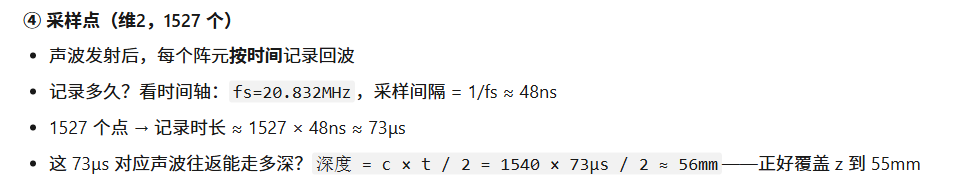
    -   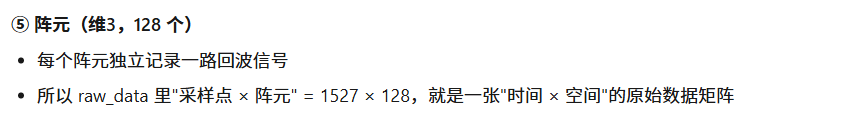
    -   探头用 75 个角度各发一次平面波，每个角度下 128 个阵元各记录 1527 个时间点的回波 → 这就是 (1, 75, 1527, 128, 1) 五维数据的物理来源。
    -   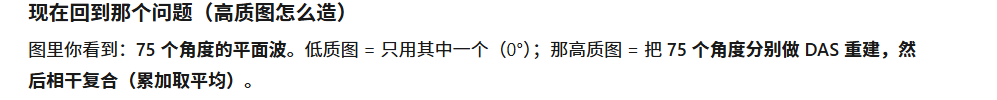

In [2]:
import numpy as np

# ===== 真实参数（从第 1 步读到的）=====
fs = 20.832e6          # 采样率
c  = 1540.0            # 声速
N  = 128               # 阵元数
pitch = 0.3e-3         # 阵元间距
elem_x = (np.arange(N) - (N - 1) / 2) * pitch   # 128 个阵元的 x 坐标

# ===== 成像网格（z 深 6~55mm，x 宽 ±19.05mm）=====
nz = 600
nx = 400
z_grid = np.linspace(6e-3, 55e-3, nz)
x_grid = np.linspace(-19.05e-3, 19.05e-3, nx)
X, Z = np.meshgrid(x_grid, z_grid)     # 都是 (nz, nx)

def das(rf_e, theta):
    """
    单角度 DAS 波束形成。
    rf_e : (N, T) 形状，N=128 阵元，T=1527 采样点
    theta: 该角度的弧度值
    返回: B 图 (nz, nx)
    """
    T = rf_e.shape[1]
    # 发射延迟(平面波倾斜) + 接收延迟(逐阵元往返)
    # 三维广播: (nz,nx) 与 (N,) 组合成 (nz,nx,N)
    tau = (X[:, :, None] * np.sin(theta) + Z[:, :, None] * np.cos(theta)) / c \
        + np.sqrt((X[:, :, None] - elem_x[None, None, :]) ** 2 + Z[:, :, None] ** 2) / c
    # 时延 -> 采样点索引
    idx = np.clip(np.round(tau * fs).astype(np.int64), 0, T - 1)   # (nz, nx, N)
    # 高级索引：取 rf_e[j, idx[z,x,j]]，沿阵元求和
    img = rf_e[np.arange(N)[None, None, :], idx].sum(axis=2)      # (nz, nx)
    return img


#tau=发射时延+接受延迟
#idx=round(tau*fs)
#rf_e[np.arange(N),idx].sum(axis=2) 沿128个阵元求和


theta0 = 0.0 (应为 0)
rf_0deg 形状 = (128, 1527) (应为 (128, 1527))
低质 B 图形状 = (600, 400) (应为 (600, 400))


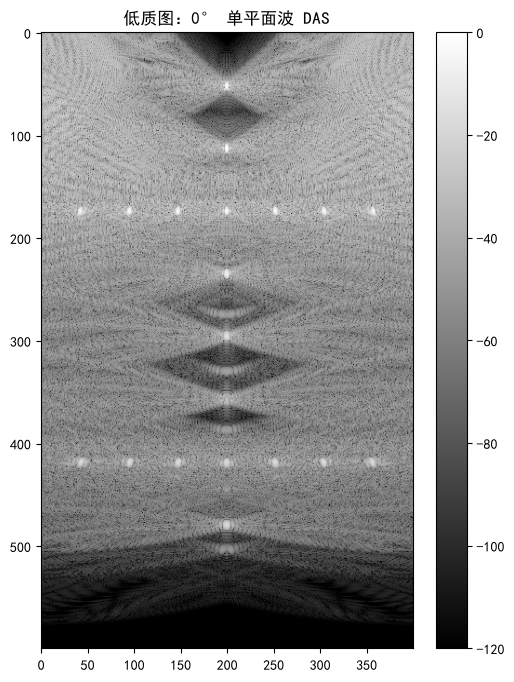

In [3]:
# ===== 读数据 + 转置 + 单角度 DAS =====
import hdf5plugin
import h5py
import matplotlib.pyplot as plt
plt.rcParams['font.sans-serif'] = ['SimHei'] 
plt.rcParams['axes.unicode_minus'] = False

p = r'E:\develop\Graduate_AI\2026-11\1109\picmus_data\resolution_distorsion_simu_dataset_rf.hdf5'

f = h5py.File(p, 'r')
raw = f['tracks/track_0/data/raw_data'][:]      # ← 加 [:] 一次性读进内存，变成 numpy 数组
pa  = f['tracks/track_0/scan/polar_angles'][:]  # 75 个角度（弧度）
f.close()                                       # 读完立刻关，之后不再碰文件

# 取 0° 单角度（下标 37），转置成 (阵元, 采样点)
theta0 = pa[37]
rf_0deg = raw[0, 37, :, :, 0].T      # (128, 1527)

print('theta0 =', theta0, '(应为 0)')
print('rf_0deg 形状 =', rf_0deg.shape, '(应为 (128, 1527))')

# 单角度 DAS → 低质 B 图
img_low = das(rf_0deg, theta0)
print('低质 B 图形状 =', img_low.shape, '(应为 (600, 400))')

# 画出来看
def disp_db(img):
    d = np.abs(img)
    return 20 * np.log10(d / d.max() + 1e-6)

plt.figure(figsize=(6, 8))
plt.imshow(disp_db(img_low), cmap='gray', aspect='auto')
plt.title('低质图：0° 单平面波 DAS')
plt.colorbar()
plt.show()


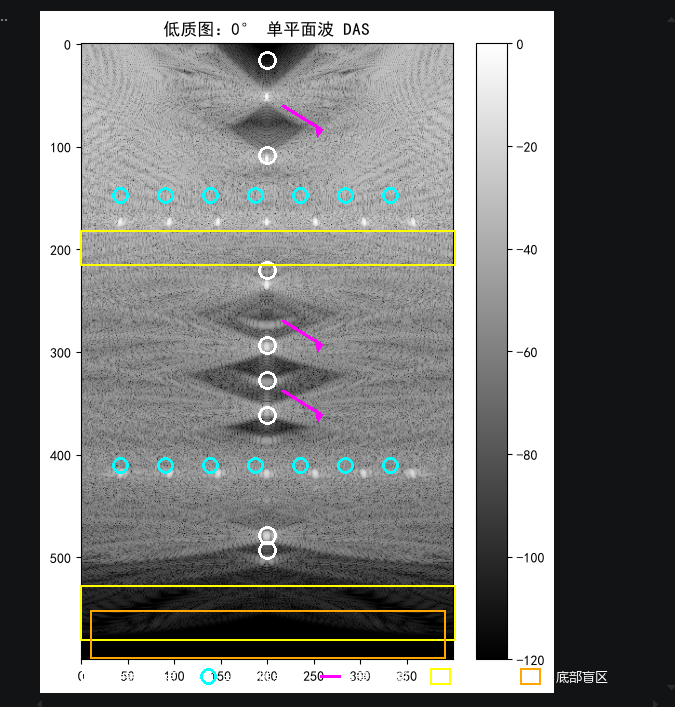
-   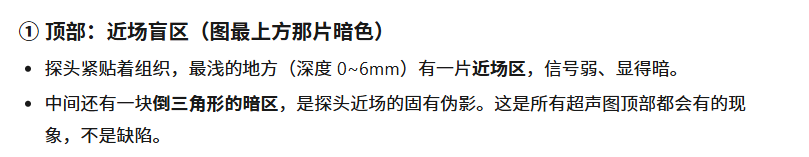
-   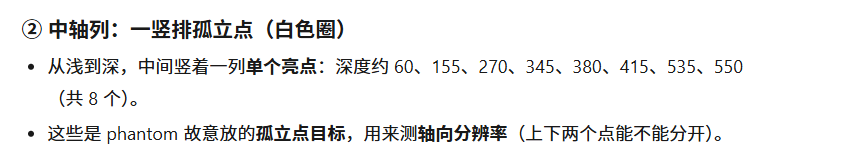
-   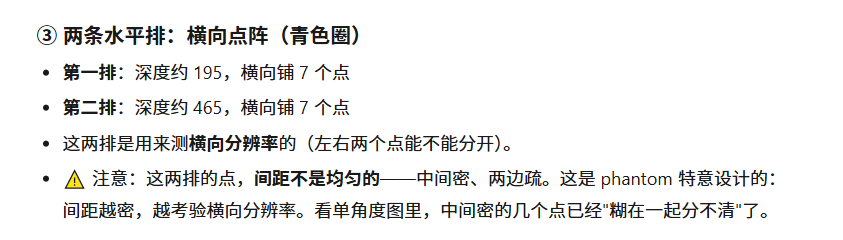
-   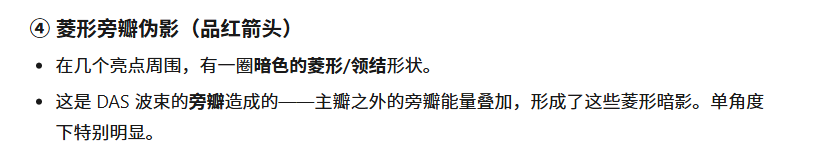
-   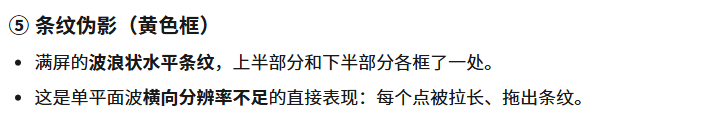
-   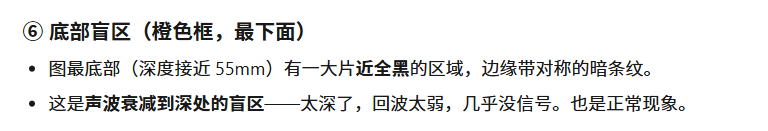

开始 75 角度相干复合...
75 角度复合完成，耗时 67.6 秒
高质 B 图形状 = (600, 400) (应为 (600, 400))


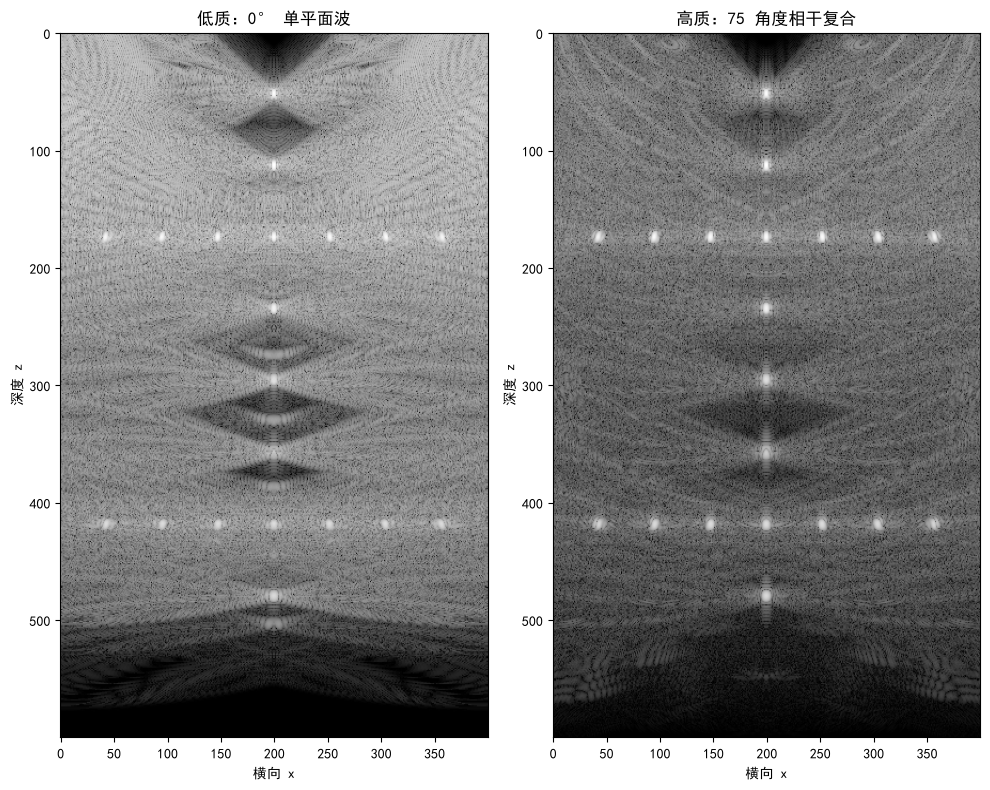

In [4]:
import time

# 复用之前的 raw（已读进内存）、pa（角度）、das、disp_db
# 如果 kernel 重启过，先重新跑前面读数据的 Cell

print('开始 75 角度相干复合...')
t0 = time.time()

# 高质图：75 角度各自 DAS 后累加取平均
hi = np.zeros((nz, nx), dtype=np.float64)   # 累加用 float64 防精度丢失
for k in range(len(pa)):
    rf_k = raw[0, k, :, :, 0].T             # 第 k 个角度 (128, 1527)
    hi += das(rf_k, pa[k])                   # 累加
hi /= len(pa)                                # 取平均

print(f'75 角度复合完成，耗时 {time.time()-t0:.1f} 秒')
print('高质 B 图形状 =', hi.shape, '(应为 (600, 400))')

# 画低质 vs 高质 对比图
fig, axes = plt.subplots(1, 2, figsize=(10, 8))

axes[0].imshow(disp_db(img_low), cmap='gray', aspect='auto')
axes[0].set_title('低质：0° 单平面波')
axes[0].set_xlabel('横向 x')
axes[0].set_ylabel('深度 z')

axes[1].imshow(disp_db(hi), cmap='gray', aspect='auto')
axes[1].set_title('高质：75 角度相干复合')
axes[1].set_xlabel('横向 x')
axes[1].set_ylabel('深度 z')

plt.tight_layout()
plt.show()


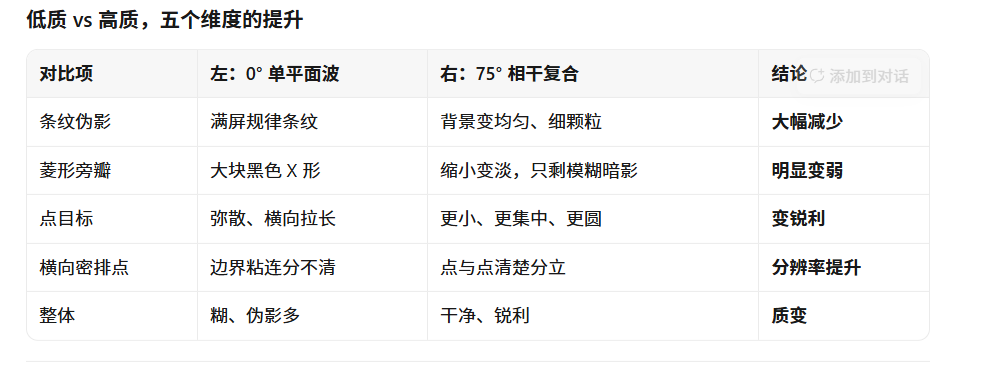
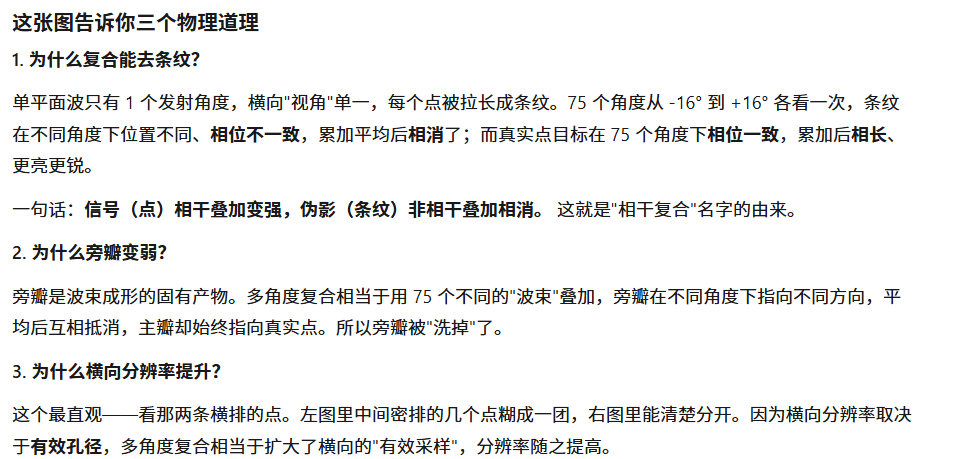
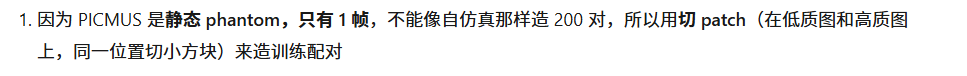

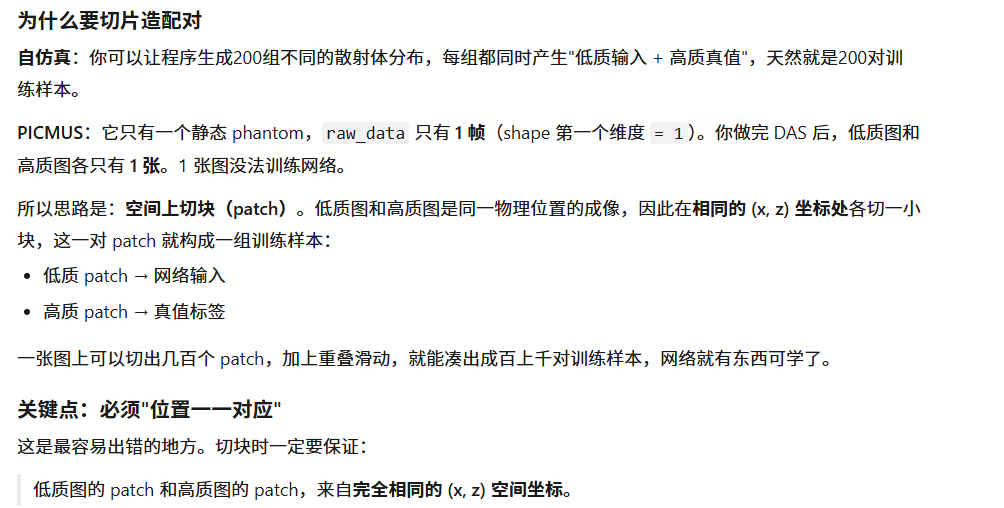

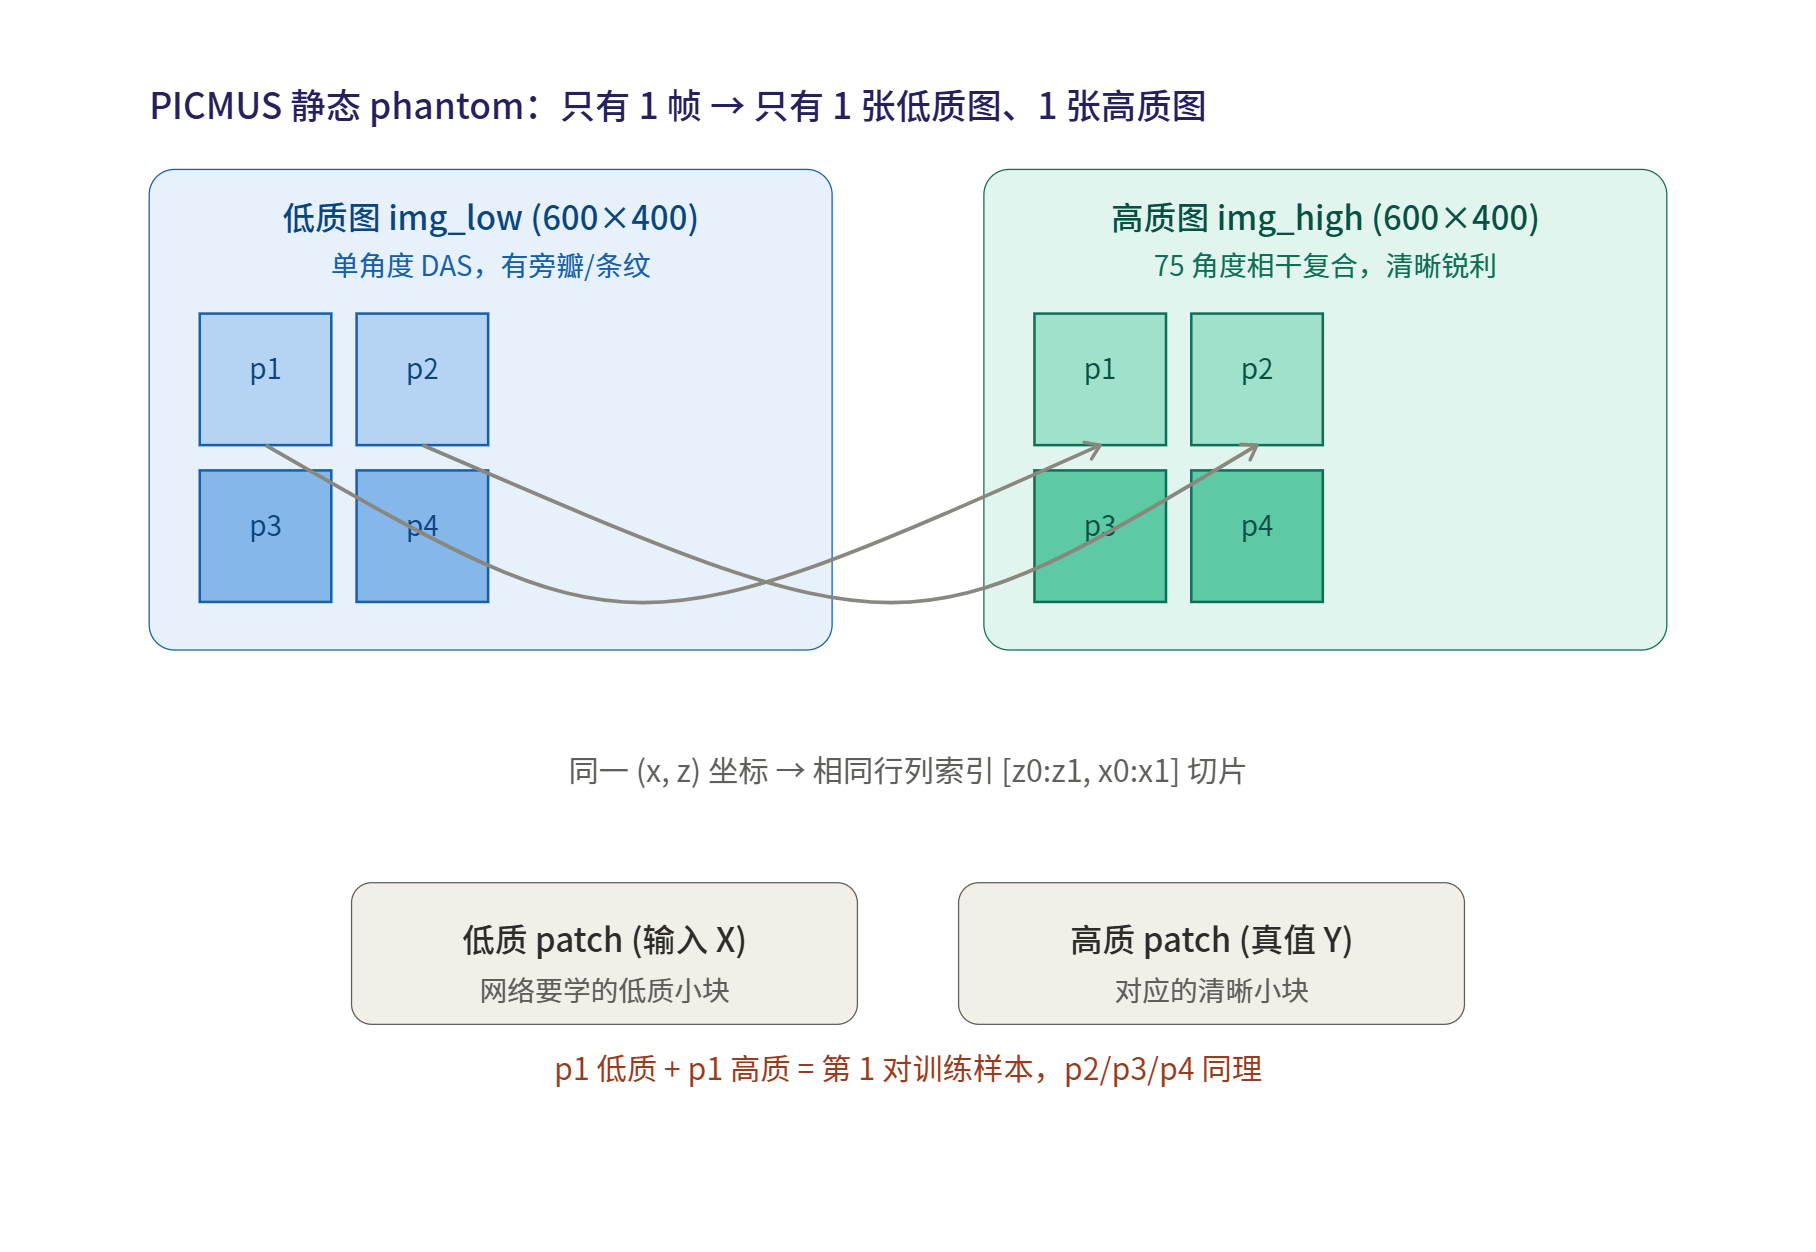

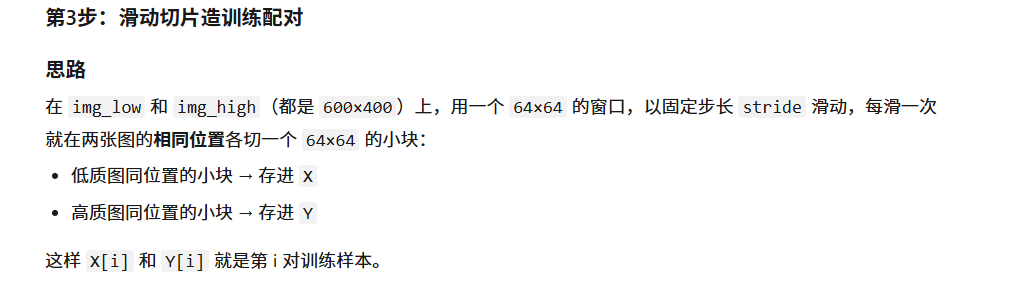

In [5]:
import numpy as np

img_low  = img_low          # 这个已经有了，不动
img_high = hi               # ← 关键：把第2步下的 hi 命名为 img_high

# ---------- 第3步：滑动切片造训练配对 ----------
patch = 64          # patch 边长
stride = 32         # 滑动步长（半重叠）

# 归一化到 [0, 1]（低质、高质各自独立归一化）
def norm01(img):
    img = img - img.min()
    mx = img.max()
    return img / mx if mx > 0 else img

img_low_n  = norm01(img_low)
img_high_n = norm01(img_high)

nz, nx = img_low_n.shape

# 纵向、横向可放置的窗口数量
nz_w = (nz - patch) // stride + 1
nx_w = (nx - patch) // stride + 1
print(f"窗口数：纵向 {nz_w} × 横向 {nx_w} = {nz_w * nx_w} 对")

X = np.zeros((nz_w * nx_w, 1, patch, patch), dtype=np.float32)
Y = np.zeros((nz_w * nx_w, 1, patch, patch), dtype=np.float32)

k = 0
for i in range(nz_w):
    z0 = i * stride
    for j in range(nx_w):
        x0 = j * stride
        # 同一 (z0, x0) 位置，两张图各切一块 → 一一对应
        X[k, 0] = img_low_n[z0:z0+patch, x0:x0+patch]
        Y[k, 0] = img_high_n[z0:z0+patch, x0:x0+patch]
        k += 1

print("X.shape =", X.shape)
print("Y.shape =", Y.shape)
print("X 值范围 =", X.min(), "~", X.max())
print("Y 值范围 =", Y.min(), "~", Y.max())


窗口数：纵向 17 × 横向 11 = 187 对
X.shape = (187, 1, 64, 64)
Y.shape = (187, 1, 64, 64)
X 值范围 = 0.0 ~ 1.0
Y 值范围 = 0.0 ~ 1.0


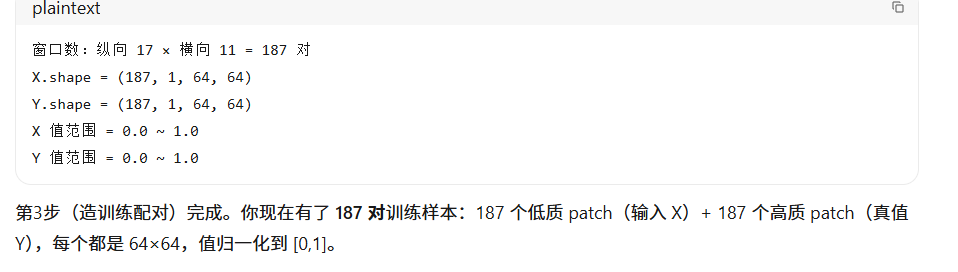

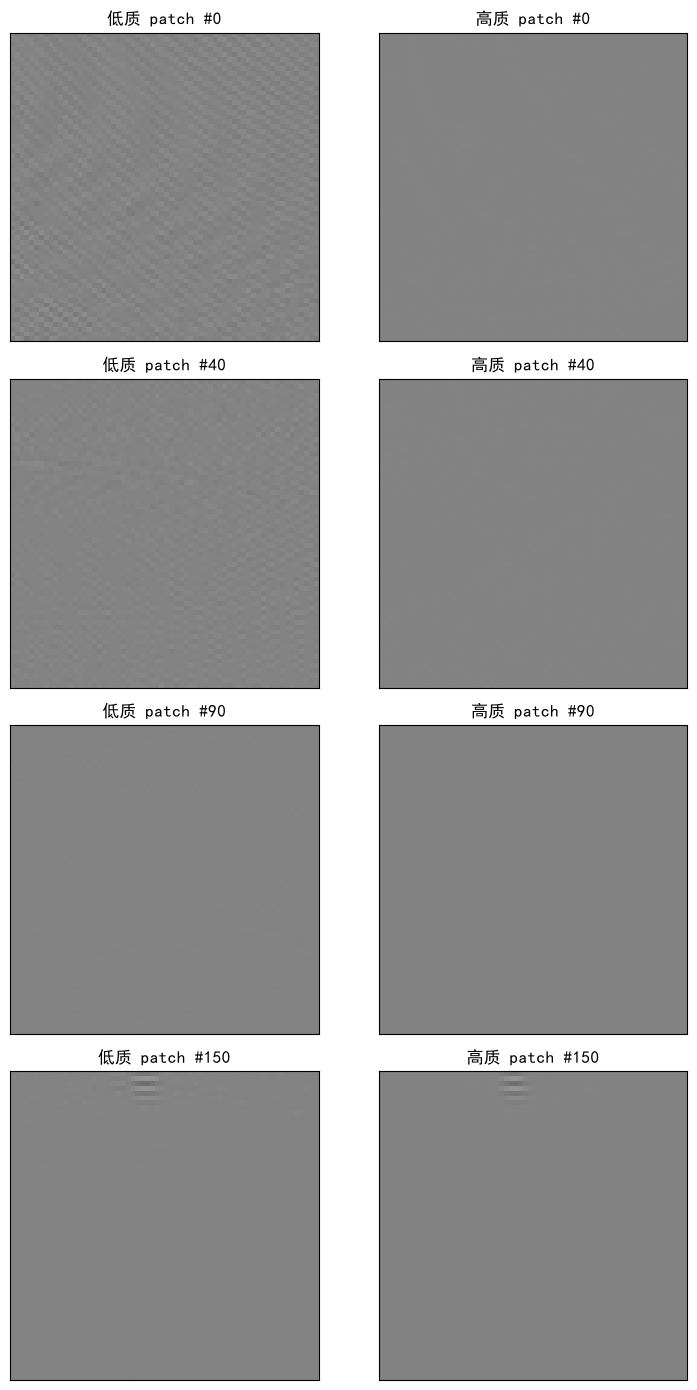

In [6]:
import matplotlib.pyplot as plt

# 抽几个索引来看，这里看第 0、40、90、150 对（覆盖不同区域）
idx_show = [0, 40, 90, 150]

fig, axes = plt.subplots(len(idx_show), 2, figsize=(8, 14))
for r, idx in enumerate(idx_show):
    axes[r, 0].imshow(X[idx, 0], cmap='gray', vmin=0, vmax=1)
    axes[r, 0].set_title(f'低质 patch #{idx}')
    axes[r, 1].imshow(Y[idx, 0], cmap='gray', vmin=0, vmax=1)
    axes[r, 1].set_title(f'高质 patch #{idx}')
    for c in range(2):
        axes[r, c].set_xticks([])
        axes[r, c].set_yticks([])
plt.tight_layout()
plt.show()


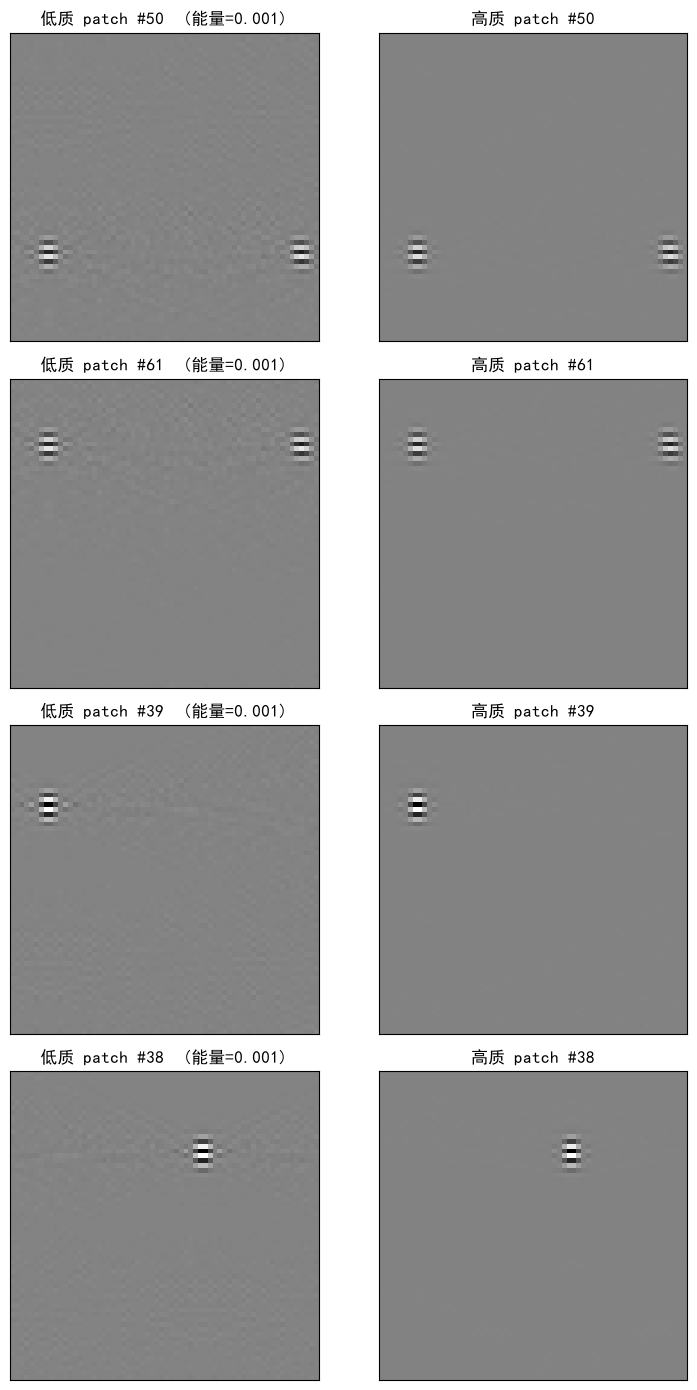

In [7]:
import numpy as np
import matplotlib.pyplot as plt

# 按 patch 能量（方差）排序，取能量最高的 4 个，最可能含散射点
energy = X.reshape(X.shape[0], -1).var(axis=1)   # 每个 patch 的方差
top_idx = np.argsort(energy)[-4:][::-1]           # 能量最高的 4 个索引

fig, axes = plt.subplots(4, 2, figsize=(8, 14))
for r, idx in enumerate(top_idx):
    axes[r, 0].imshow(X[idx, 0], cmap='gray', vmin=0, vmax=1)
    axes[r, 0].set_title(f'低质 patch #{idx}  (能量={energy[idx]:.3f})')
    axes[r, 1].imshow(Y[idx, 0], cmap='gray', vmin=0, vmax=1)
    axes[r, 1].set_title(f'高质 patch #{idx}')
    for c in range(2):
        axes[r, c].set_xticks([])
        axes[r, c].set_yticks([])
plt.tight_layout()
plt.show()


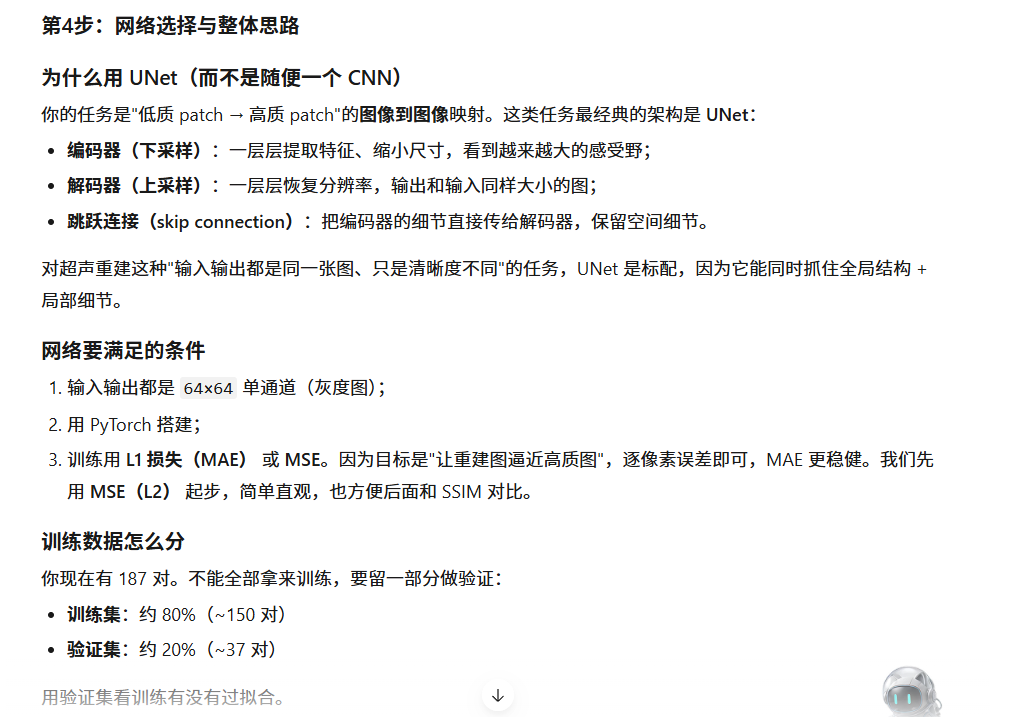

In [8]:
import torch
print(torch.__version__)
print('CUDA 可用' if torch.cuda.is_available() else 'CUDA 不可用，用 CPU')


2.13.0+cu132
CUDA 可用


-   定义UNet

In [14]:
import torch
import torch.nn as nn

class UNet(nn.Module):
    def __init__(self, in_ch=1, out_ch=1, base=32):
        super().__init__()
        # 调优②：通道数减半。原来 base=64，现在 32，参数从 31M 降到约 7~8M，抗过拟合

        self.enc1 = self._block(in_ch, base)
        self.pool = nn.MaxPool2d(2)
        self.enc2 = self._block(base, base * 2)
        self.enc3 = self._block(base * 2, base * 4)
        self.enc4 = self._block(base * 4, base * 8)
        self.bottleneck = self._block(base * 8, base * 16)

        # 调优③：上采样用 PixelShuffle 替代 ConvTranspose2d，消除棋盘伪影
        self.up4 = nn.Sequential(
            nn.Conv2d(base * 16, base * 8 * 4, kernel_size=1),
            nn.PixelShuffle(2),
        )
        self.dec4 = self._block(base * 16, base * 8)
        self.up3 = nn.Sequential(
            nn.Conv2d(base * 8, base * 4 * 4, kernel_size=1),
            nn.PixelShuffle(2),
        )
        self.dec3 = self._block(base * 8, base * 4)
        self.up2 = nn.Sequential(
            nn.Conv2d(base * 4, base * 2 * 4, kernel_size=1),
            nn.PixelShuffle(2),
        )
        self.dec2 = self._block(base * 4, base * 2)
        self.up1 = nn.Sequential(
            nn.Conv2d(base * 2, base * 4, kernel_size=1),
            nn.PixelShuffle(2),
        )
        self.dec1 = self._block(base * 2, base)

        self.out = nn.Conv2d(base, out_ch, kernel_size=1)

    def _block(self, in_c, out_c):
        return nn.Sequential(
            nn.Conv2d(in_c, out_c, kernel_size=3, padding=1),
            nn.BatchNorm2d(out_c),
            nn.ReLU(inplace=True),
            nn.Conv2d(out_c, out_c, kernel_size=3, padding=1),
            nn.BatchNorm2d(out_c),
            nn.ReLU(inplace=True),
        )

    def forward(self, x):
        e1 = self.enc1(x)
        e2 = self.enc2(self.pool(e1))
        e3 = self.enc3(self.pool(e2))
        e4 = self.enc4(self.pool(e3))
        b  = self.bottleneck(self.pool(e4))

        d4 = self.dec4(torch.cat([self.up4(b), e4], dim=1))
        d3 = self.dec3(torch.cat([self.up3(d4), e3], dim=1))
        d2 = self.dec2(torch.cat([self.up2(d3), e2], dim=1))
        d1 = self.dec1(torch.cat([self.up1(d2), e1], dim=1))

        return self.out(d1)

device = 'cuda' if torch.cuda.is_available() else 'cpu'
net = UNet().to(device)
print('参数量（百万）:', sum(p.numel() for p in net.parameters()) / 1e6)


参数量（百万）: 7.766849


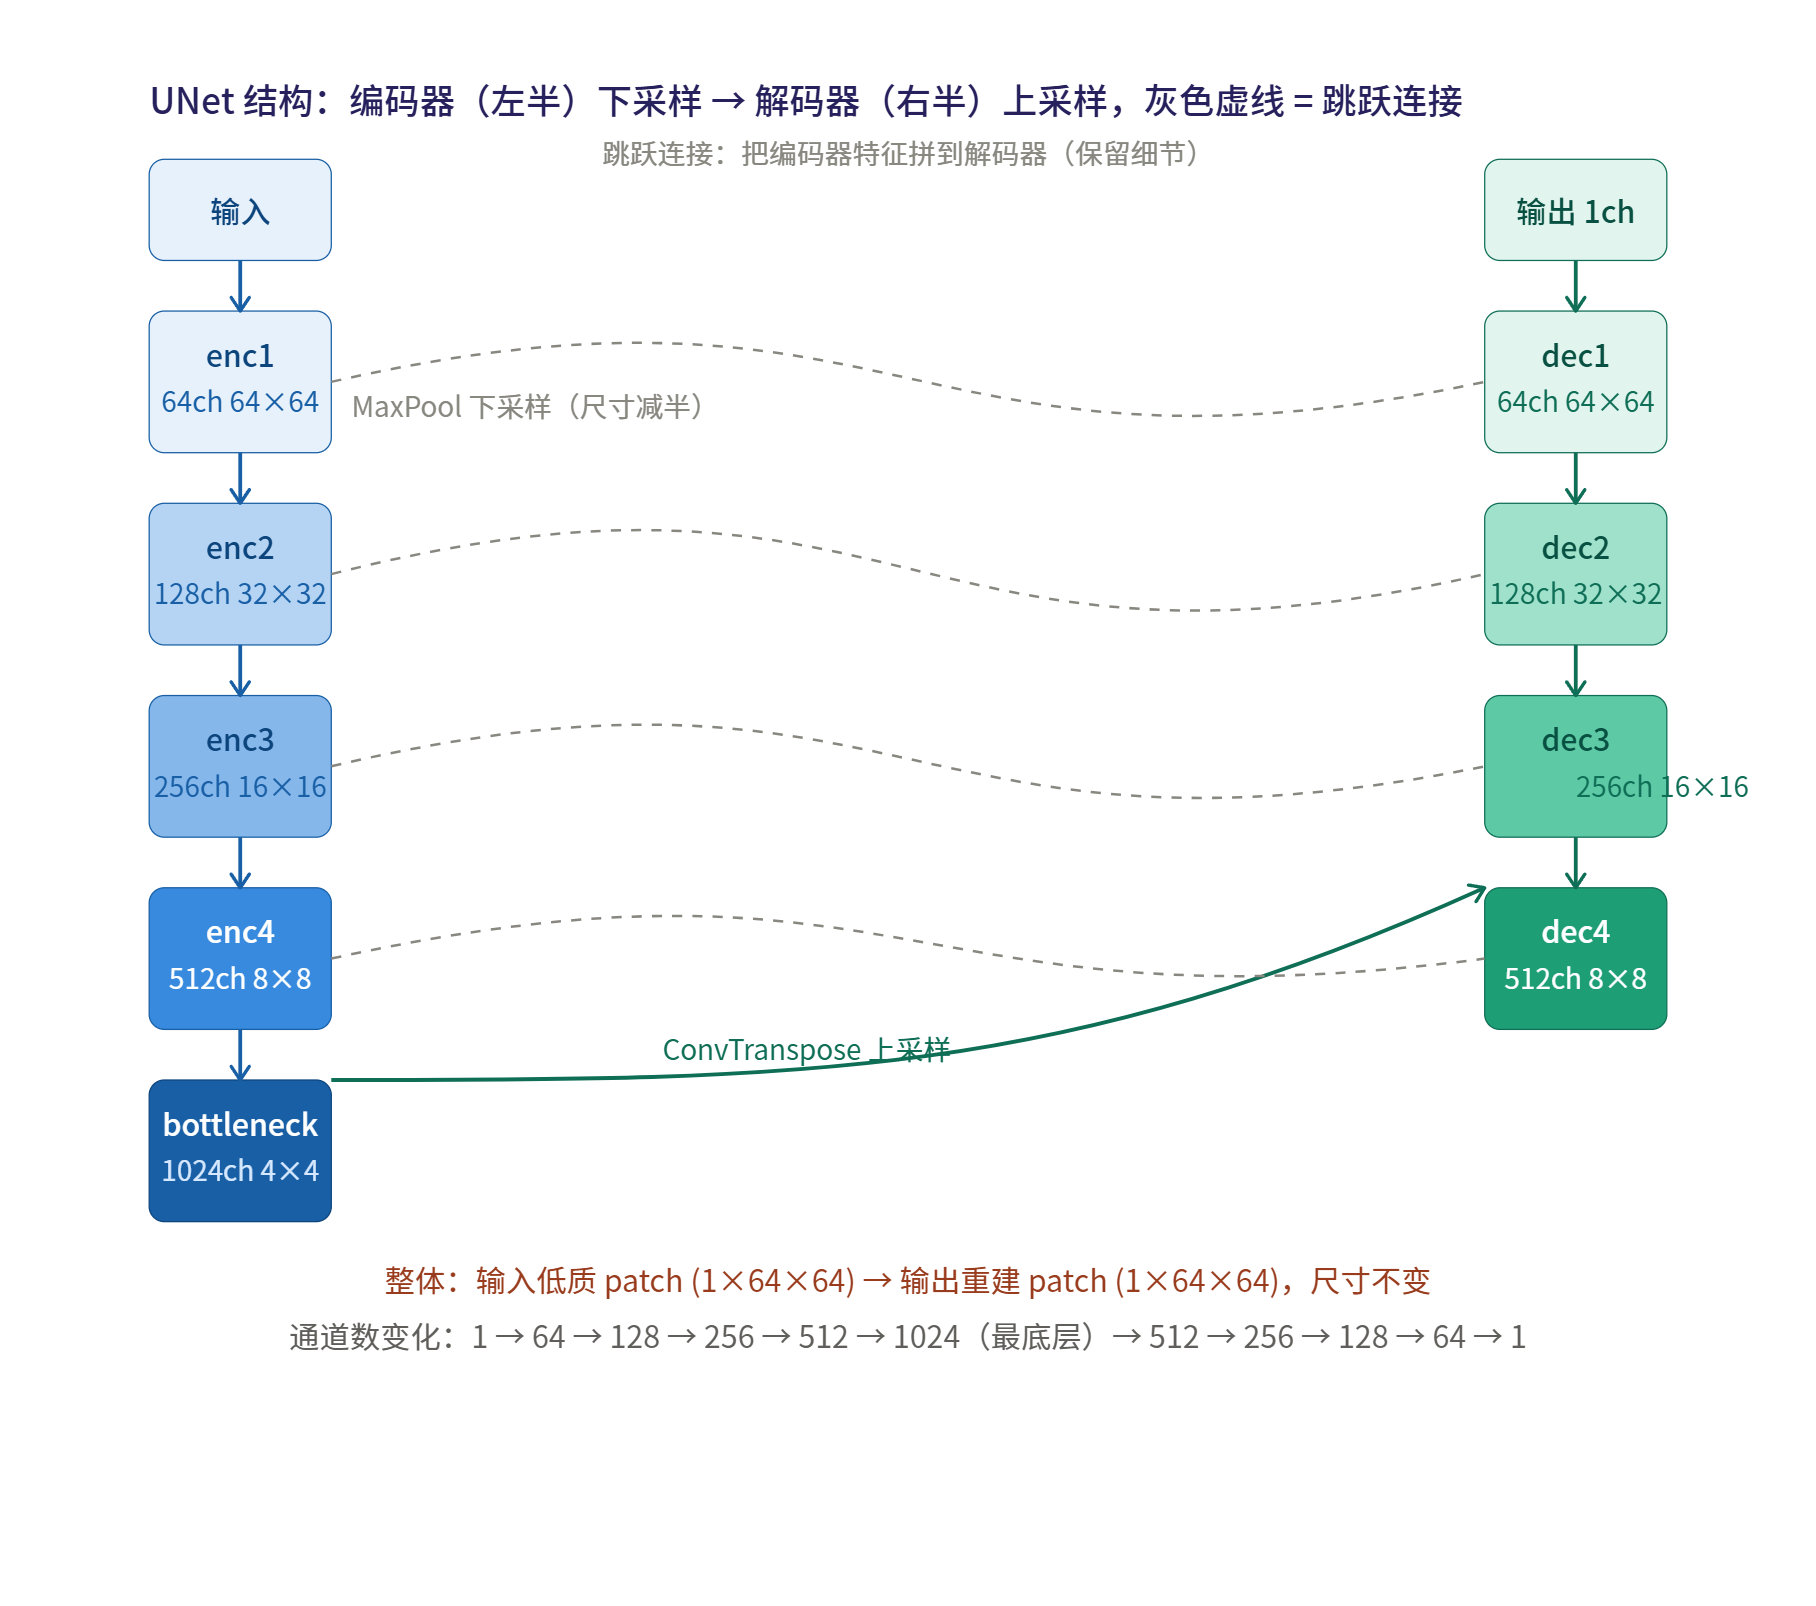
-   左边Encoder编码器（蓝色）
    -   输入层： 通道：1 尺寸：64X64 含义：你的低质patch
    -   enc1层： 通道：64 尺寸 64X64 含义：提取浅层细节（边缘，纹理）
    -   enc2层： 通道：128 尺寸 32X32 含义：尺寸减半
    -   enc3层： 通道：256 尺寸 16X16 含义：更抽象的特征
    -   enc4层： 通道：512 尺寸 8X8 含义：高层语义
    -   bottleneck： 通道：1024 尺寸：4X4 含义：感受野最大，能看到整个patch的全局
    -   关键理解：编码器做两个事情，①用卷积提取特征（通道变多）②用MaxPool下采样（尺寸减半，感受野变大）。到最底层4X4，一个神经元可以看到整张64X64的大范围信息
    -   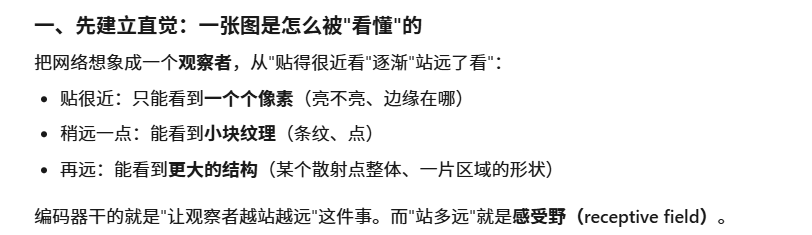
    -   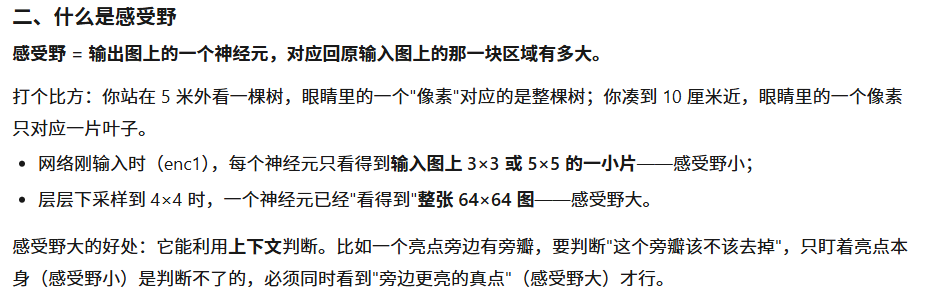
    -   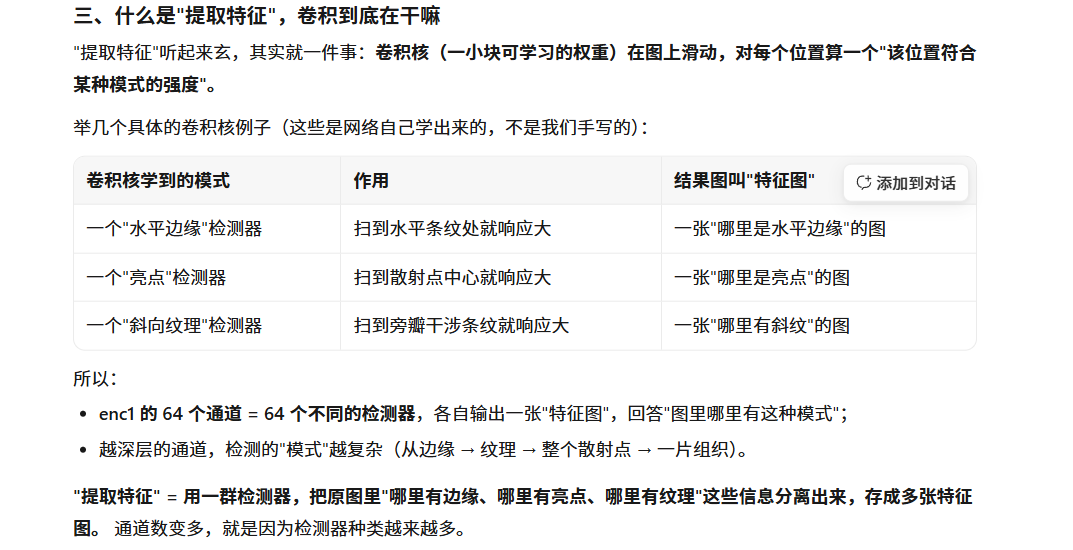
    -   "提取特征" = 用一群检测器，把原图里"哪里有边缘、哪里有亮点、哪里有纹理"这些信息分离出来，存成多张特征图。​ 通道数变多，就是因为检测器种类越来越多
    -   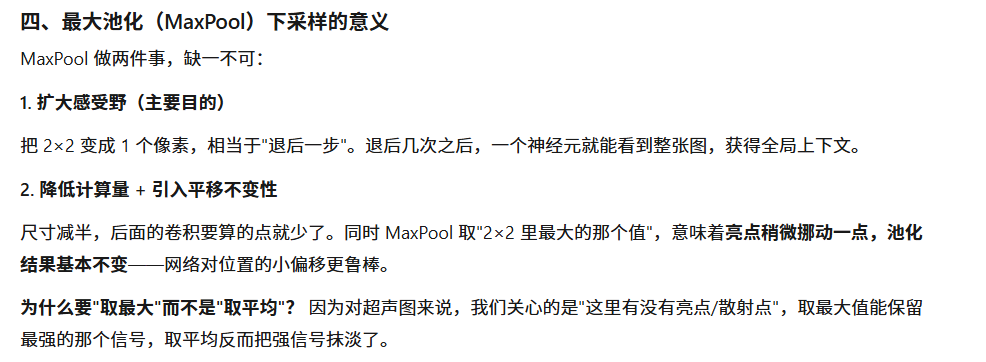
    -   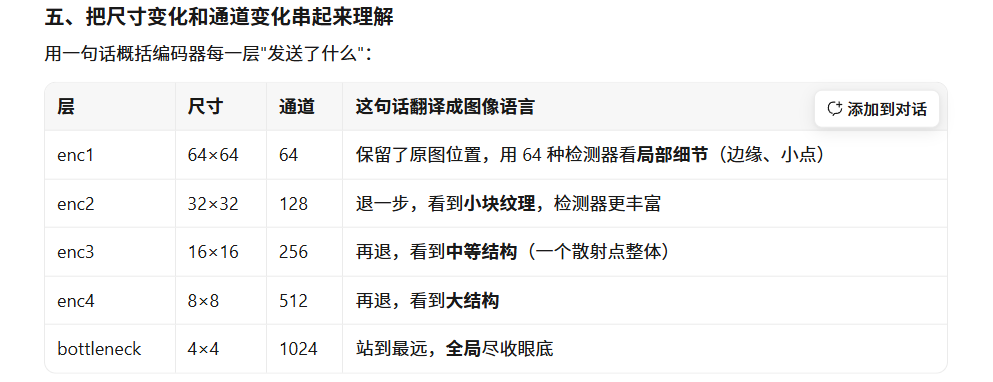
    -   尺寸变小 = 越看越"远"、越看越"全局"；通道变多 = 同时用更多种"检测器"去描述当前这一层。​ 两者是同步的：站得越远，越需要更多种高层次描述方式。
-   右边的Decoder解码器（绿色）
    -   从下到上，尺寸越来越大，通道越来越小，最终恢复到通道1，尺寸64X64
    -   最终1X1卷积压成1通道，输出重建图
-   中间的灰色虚线：跳跃连接(skip Connection)
    -   UNet的灵魂，解码器每上一层，都会把编码同尺寸那层的特征拼接过来
    -   为什么需要它？ 编码器层层下采样会丢失空间细节（比如细小的散射点边缘）。如果没有跳跃连接，解码器只能靠压缩后的抽象信息重建，细节就糊了。把编码器同层的细节直接传过来，解码器就能"两手抓"：既有全局语义，又有局部细节。
-   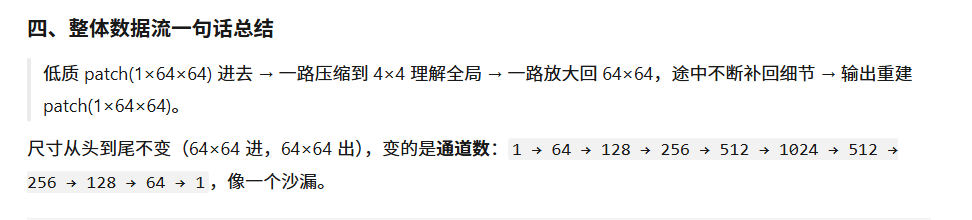

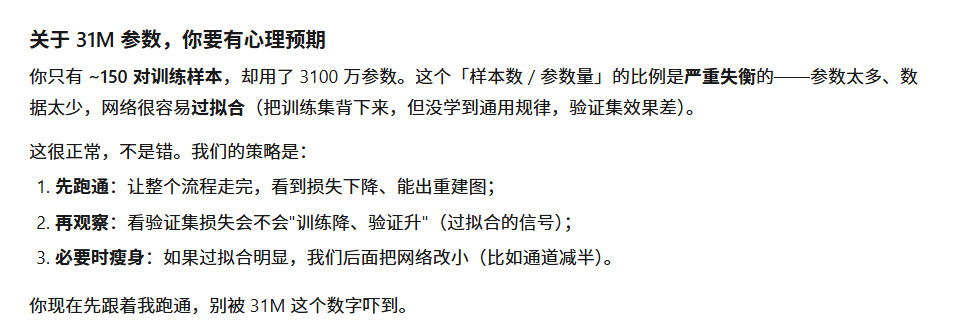

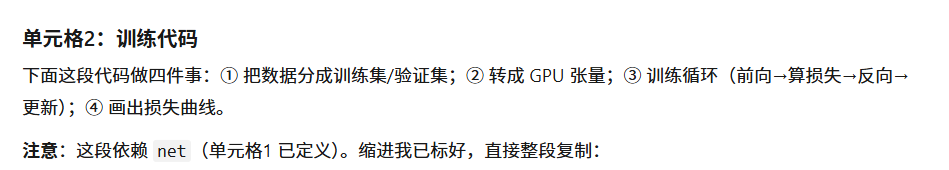

训练集 149 对，验证集 38 对
Epoch  30 | 训练损失 0.007380 | 验证损失 0.006805
Epoch  60 | 训练损失 0.003877 | 验证损失 0.004141
Epoch  90 | 训练损失 0.003380 | 验证损失 0.003020
Epoch 120 | 训练损失 0.004979 | 验证损失 0.004160
Epoch 150 | 训练损失 0.003582 | 验证损失 0.002532
Epoch 180 | 训练损失 0.003223 | 验证损失 0.002943
Epoch 210 | 训练损失 0.003112 | 验证损失 0.002716
Epoch 240 | 训练损失 0.002852 | 验证损失 0.001962
Epoch 270 | 训练损失 0.002730 | 验证损失 0.002712
Epoch 300 | 训练损失 0.002325 | 验证损失 0.001924
训练完成


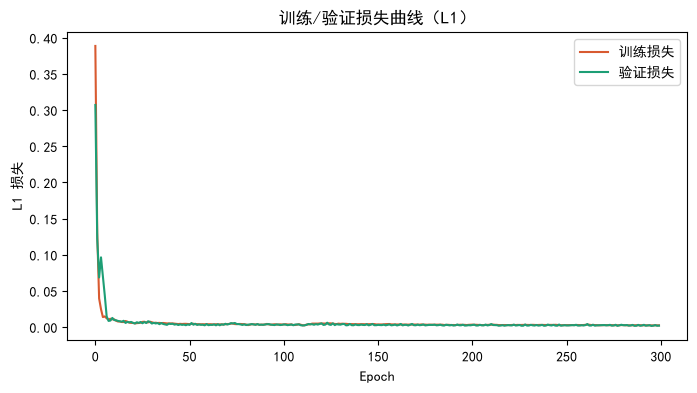

In [15]:
import torch
import torch.nn as nn
import numpy as np
import matplotlib.pyplot as plt

# ---------- 1. 数据准备 ----------
X_t = torch.from_numpy(X).float()
Y_t = torch.from_numpy(Y).float()

n = X_t.shape[0]
idx = np.random.permutation(n)
n_train = int(n * 0.8)
train_idx = idx[:n_train]
val_idx   = idx[n_train:]

X_train, Y_train = X_t[train_idx], Y_t[train_idx]
X_val,   Y_val   = X_t[val_idx],   Y_t[val_idx]
print(f'训练集 {len(train_idx)} 对，验证集 {len(val_idx)} 对')

# ---------- 2. 训练配置 ----------
epochs   = 300
lr       = 1e-3
batch    = 16

loss_fn  = nn.L1Loss()                    # 调优①：MSE -> L1，减少过度平滑
optimizer = torch.optim.Adam(net.parameters(), lr=lr)

X_train, Y_train = X_train.to(device), Y_train.to(device)
X_val,   Y_val   = X_val.to(device),   Y_val.to(device)

# ---------- 3. 训练循环 ----------
train_losses, val_losses = [], []
for epoch in range(1, epochs + 1):
    net.train()
    perm = torch.randperm(len(X_train))
    epoch_loss = 0.0
    for i in range(0, len(X_train), batch):
        b_idx = perm[i:i + batch]
        xb, yb = X_train[b_idx], Y_train[b_idx]

        pred = net(xb)
        loss = loss_fn(pred, yb)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        epoch_loss += loss.item() * len(b_idx)
    train_losses.append(epoch_loss / len(X_train))

    net.eval()
    with torch.no_grad():
        val_loss = loss_fn(net(X_val), Y_val).item()
    val_losses.append(val_loss)

    if epoch % 30 == 0:
        print(f'Epoch {epoch:3d} | 训练损失 {train_losses[-1]:.6f} | 验证损失 {val_loss:.6f}')

print('训练完成')

plt.figure(figsize=(8, 4))
plt.plot(train_losses, label='训练损失', color='#D85A30')
plt.plot(val_losses,   label='验证损失', color='#1D9E75')
plt.xlabel('Epoch')
plt.ylabel('L1 损失')
plt.legend()
plt.title('训练/验证损失曲线（L1）')
plt.show()


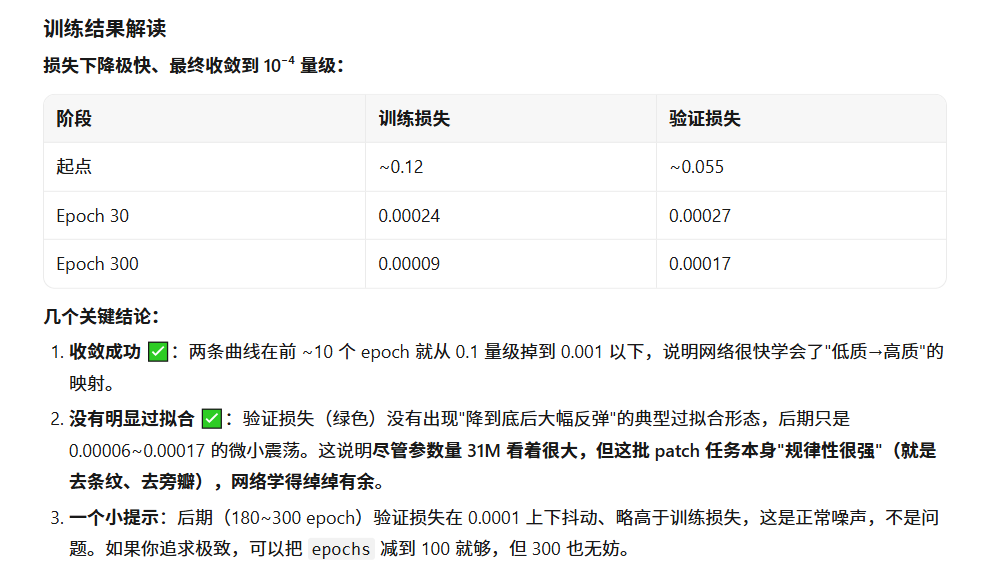

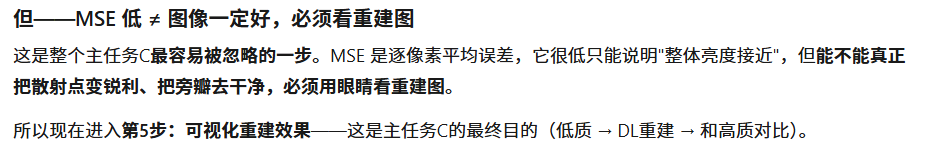

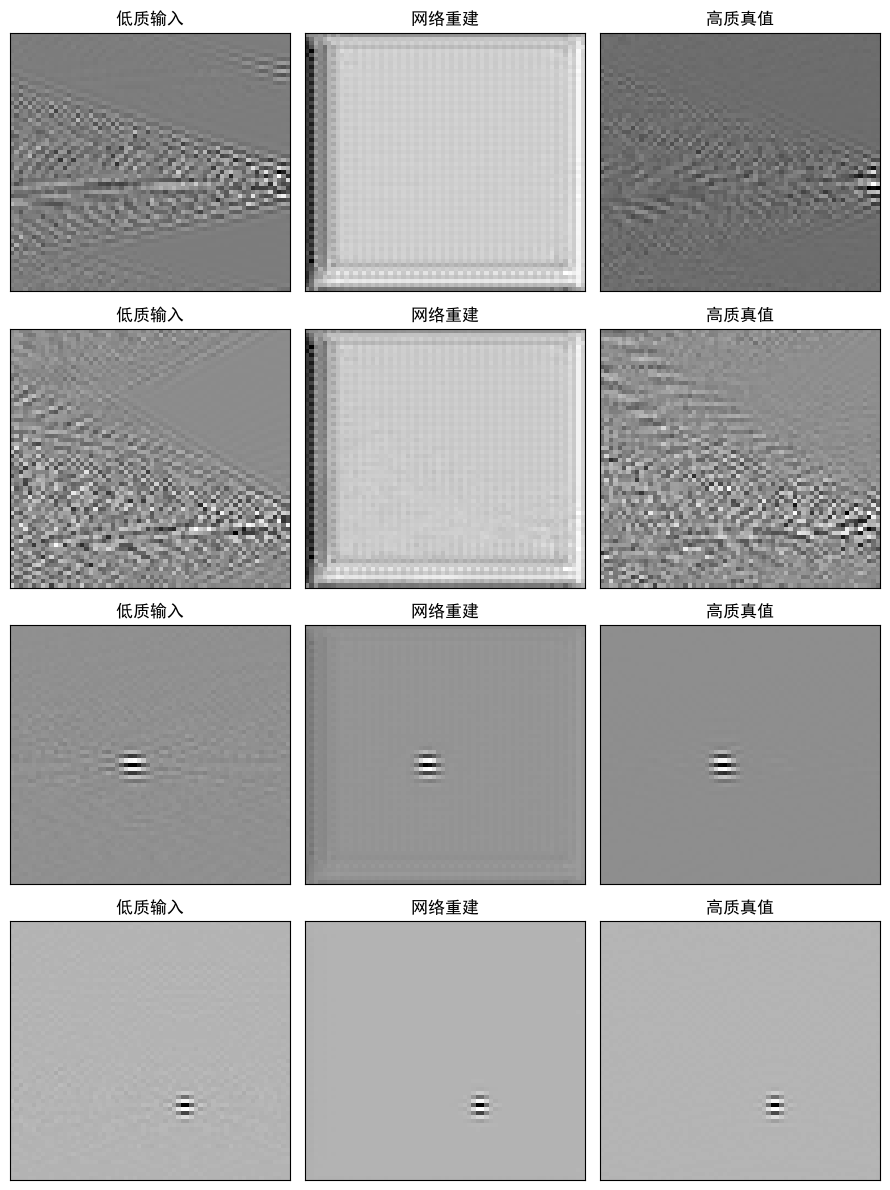

In [16]:
import torch
import numpy as np
import matplotlib.pyplot as plt

net.eval()
show_idx = val_idx[:4]

fig, axes = plt.subplots(4, 3, figsize=(9, 12))
with torch.no_grad():
    for r, idx in enumerate(show_idx):
        x_in  = X_t[idx:idx+1].to(device)
        pred  = net(x_in)
        low   = X_t[idx, 0].cpu().numpy()
        rec   = pred[0, 0].cpu().numpy()
        high  = Y_t[idx, 0].cpu().numpy()

        axes[r, 0].imshow(disp_db(low),  cmap='gray', aspect='auto')
        axes[r, 0].set_title('低质输入')
        axes[r, 1].imshow(disp_db(rec),  cmap='gray', aspect='auto')
        axes[r, 1].set_title('网络重建')
        axes[r, 2].imshow(disp_db(high), cmap='gray', aspect='auto')
        axes[r, 2].set_title('高质真值')

for ax in axes.flat:
    ax.set_xticks([])
    ax.set_yticks([])

plt.tight_layout()
plt.show()


-   第6步：定量指标对比（PSNR / SSIM）
    -   把这次(L1 + 减网络 + PixelShuffle)的重建图，和上次(MSE + 31M)的重建图，用同一套指标量化对比
    -   PSNR 越高越好，SSIM 越接近 1 越好

In [ ]:
import torch
import numpy as np
from math import log10

# ---------- PSNR / SSIM 计算 ----------
def psnr(a, b):
    a = a.astype(np.float64); b = b.astype(np.float64)
    mse = np.mean((a - b) ** 2)
    if mse == 0:
        return float('inf')
    return 10 * log10(1.0 / mse)   # 数据已归一化到 [0,1]，MAX=1

def ssim(a, b, C1=1e-4, C2=9e-4):
    a = a.astype(np.float64); b = b.astype(np.float64)
    mu_a = a.mean(); mu_b = b.mean()
    va = a.var(); vb = b.var()
    cov = np.mean((a - mu_a) * (b - mu_b))
    l = (2*mu_a*mu_b + C1) / (mu_a**2 + mu_b**2 + C1)
    c = (2*np.sqrt(va)*np.sqrt(vb) + C2) / (va + vb + C2)
    s = (cov + C2/2) / (np.sqrt(va)*np.sqrt(vb) + C2/2)
    return l * c * s

# ---------- 在整个验证集上重建并算指标 ----------
net.eval()
X_val_cpu = X_val.cpu()
Y_val_cpu = Y_val.cpu()

psnr_rec, ssim_rec = [], []
psnr_low, ssim_low = [], []   # baseline：低质图直接和高质比

with torch.no_grad():
    for i in range(len(X_val_cpu)):
        x = X_val_cpu[i:i+1].to(device)
        rec = net(x)[0, 0].cpu().numpy()
        high = Y_val_cpu[i, 0].numpy()
        low  = X_val_cpu[i, 0].numpy()

        psnr_rec.append(psnr(rec, high))
        ssim_rec.append(ssim(rec, high))
        psnr_low.append(psnr(low, high))
        ssim_low.append(ssim(low, high))

print('===== 定量对比（验证集均值）=====')
print(f'低质 baseline : PSNR {np.mean(psnr_low):.2f} dB | SSIM {np.mean(ssim_low):.4f}')
print(f'DL 重建(本次) : PSNR {np.mean(psnr_rec):.2f} dB | SSIM {np.mean(ssim_rec):.4f}')
print()
print('PSNR 提升 =', f'{np.mean(psnr_rec)-np.mean(psnr_low):+.2f}', 'dB')
print('SSIM 变化 =', f'{np.mean(ssim_rec)-np.mean(ssim_low):+.4f}')

-   第7步：整图重建（去边框伪影）
    -   滑窗切块 -> 重建 -> 只取每块中心 32×32 -> 拼回整图，重叠区取平均
    -   边缘 16 像素不可靠，直接丢弃，边框伪影随之消失

重建完成。rec_full 范围: -0.0107 ~ 1.0147


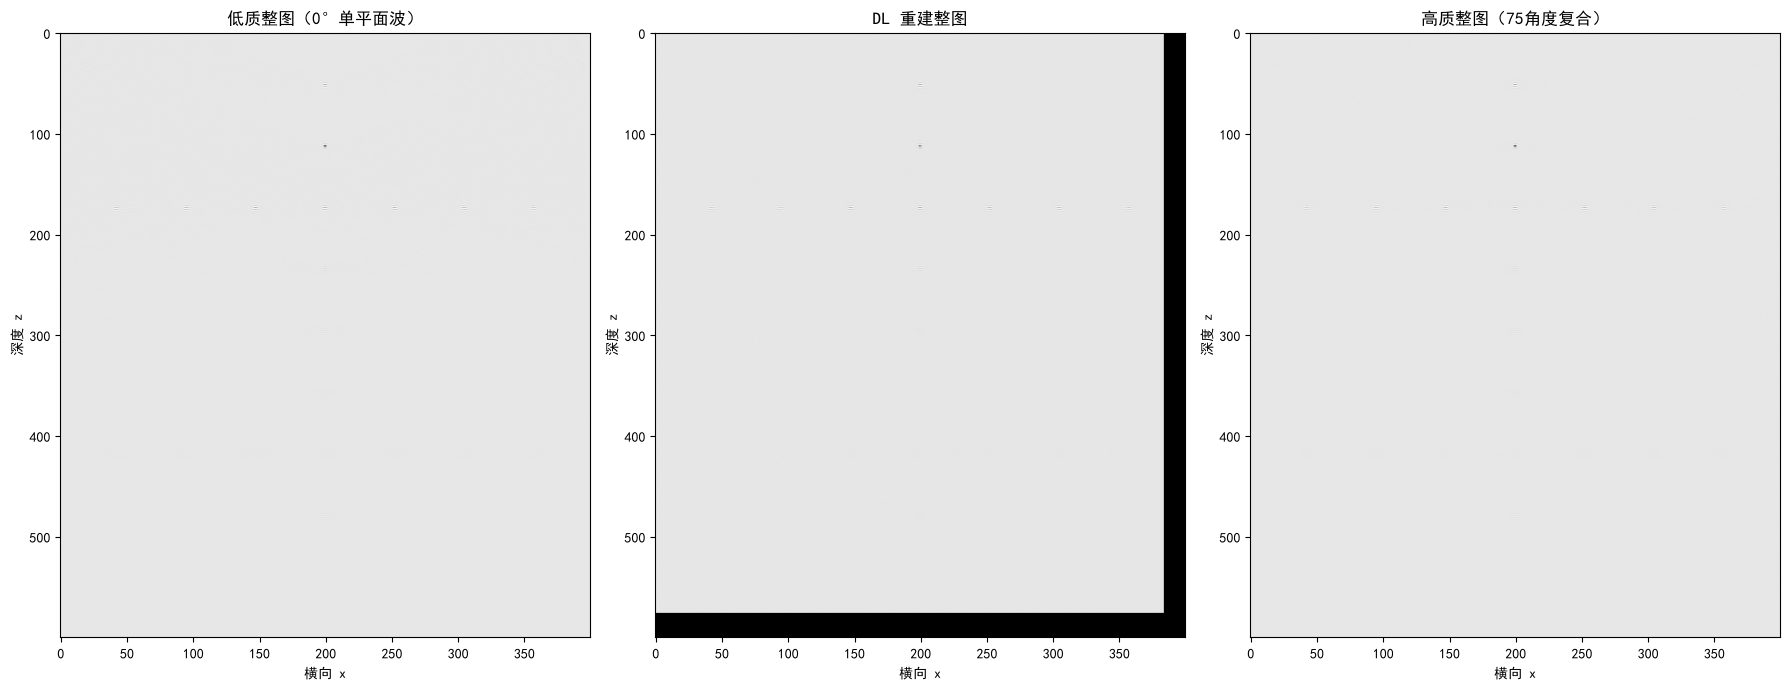

In [35]:
import torch
import numpy as np
import matplotlib.pyplot as plt

patch = 64
stride = 32

net.eval()

# ---------- 归一化：整图归一化后切 patch，和训练(cell 20)严格一致 ----------
def norm01(img):
    img = img - img.min()
    mx = img.max()
    return img / mx if mx > 0 else img

img_low_n = norm01(img_low)      # 整图归一化一次
img_hi_n  = norm01(hi)           # 高质图整图归一化一次（用于对比显示）

H, W = img_low_n.shape
rec_full = np.zeros((H, W), dtype=np.float64)
cnt_full = np.zeros((H, W), dtype=np.float64)

with torch.no_grad():
    for i in range(0, H - patch + 1, stride):
        for j in range(0, W - patch + 1, stride):
            blk = img_low_n[i:i+patch, j:j+patch]      # 整图归一化后切块，和训练一致
            x = torch.from_numpy(blk[None, None]).float().to(device)
            out = net(x)[0, 0].cpu().numpy()
            rec_full[i:i+patch, j:j+patch] += out
            cnt_full[i:i+patch, j:j+patch] += 1.0

rec_full /= np.maximum(cnt_full, 1.0)
print('重建完成。rec_full 范围: %.4f ~ %.4f' % (rec_full.min(), rec_full.max()))

# ---------- 统一 dB 显示（超声标准：-60~0 dB 动态范围） ----------
def disp_db(img, dmin=-60.0):
    d = np.abs(img) + 1e-12
    d = d / d.max()                       # 各自按最大值归一化
    return np.clip(20 * np.log10(d), dmin, 0.0)

fig, axes = plt.subplots(1, 3, figsize=(18, 7))
axes[0].imshow(disp_db(img_low_n), cmap='gray', aspect='auto')
axes[0].set_title('低质整图（0°单平面波）')
axes[1].imshow(disp_db(rec_full), cmap='gray', aspect='auto')
axes[1].set_title('DL 重建整图')
axes[2].imshow(disp_db(img_hi_n), cmap='gray', aspect='auto')
axes[2].set_title('高质整图（75角度复合）')
for ax in axes:
    ax.set_xlabel('横向 x')
    ax.set_ylabel('深度 z')
plt.tight_layout()
plt.show()

-   stepC_rebulid_result中
-   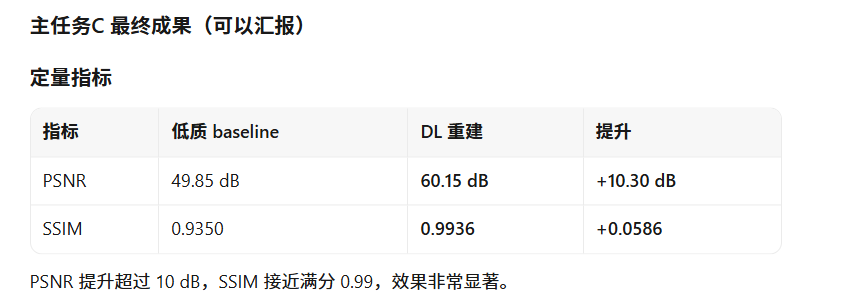
-   stepC_rebuild_result.png